# Titanic — What the group model learned (SHAP)

**Question:** notebook 04 showed that `GroupSurvival` helps, mostly for women in 3rd class, and hurts for men whose
known group members all survived. *How* does the model use the feature, and does the explanation support that story?

**Method.** SHAP splits one prediction into additive contributions, one per feature:
`base value + sum of contributions = model output`. The model is the tuned XGBoost + group from notebook 04
(tree models get exact, fast SHAP values). Rules followed:

- **Only unseen rows are explained.** Each of the 5 shared CV folds fits its own nested-CV model on the training part
  and explains the validation part, so every passenger is explained once, by a model that never saw them.
- **The explained output is stated:** the raw margin, i.e. the **log-odds of survival**. Positive = pushes towards
  survived. Probabilities are not additive, log-odds are.
- **Every explanation is checked:** base value + contributions must reproduce the model's margin for that row.
- SHAP describes the model, not the world: a large contribution is not a cause of survival.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import sklearn
import xgboost
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

sys.path.insert(0, str(Path("../src").resolve()))
from titanic.data import load_raw
from titanic.features import CATEGORICAL_FEATURES, make_preprocessor

SEED = 42
DATA_DIR = Path("../data/raw")
FIG_DIR = Path("../reports/figures")
REPORT_DIR = Path("../reports")
N_THREADS = 8

sns.set_theme(style="whitegrid", palette="deep")
print(f"shap {shap.__version__}, xgboost {xgboost.__version__}, scikit-learn {sklearn.__version__}")


def save_fig(fig, name):
    """Save a figure to reports/figures for the README and the blog post."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")


train = load_raw(DATA_DIR / "train.csv")
X = train.drop(columns="Survived")
y = train["Survived"]
print(f"X: {X.shape}, y: {y.shape}")

C:\Users\G6X\Desktop\BeyinV2Projeler\kaggle-titanic\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


shap 0.52.0, xgboost 3.4.1, scikit-learn 1.9.1
X: (891, 11), y: (891,)


## 1. Out-of-fold SHAP values

Same outer folds and the same XGBoost grid as notebook 04, so the five fold models are the ones behind its
"XGBoost (tuned) + group" score. The preprocessing is applied first and the XGBoost step is explained on the
transformed columns (scaled numbers, 0/1 flags, one-hot categories).

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
inner_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
xgb_grid = {
    "model__max_depth": [2, 3, 4],
    "model__learning_rate": [0.03, 0.1],
    "model__n_estimators": [100, 300],
    "model__min_child_weight": [1, 5],
}

n_rows = len(X)
shap_values = None
base_values = np.zeros(n_rows)
margins = np.zeros(n_rows)
raw_columns = None
fold_rows = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X, y), start=1):
    estimator = XGBClassifier(subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=N_THREADS)
    search = GridSearchCV(Pipeline([("prep", make_preprocessor(group_survival=True)), ("model", estimator)]),
                          xgb_grid, cv=inner_cv, scoring="accuracy")
    search.fit(X.iloc[train_idx], y.iloc[train_idx])
    prep = search.best_estimator_.named_steps["prep"]
    model = search.best_estimator_.named_steps["model"]

    X_valid = X.iloc[valid_idx]
    transformed = np.asarray(prep.transform(X_valid), dtype=float)
    explanation = shap.TreeExplainer(model)(transformed)  # tree-path-dependent, output = log-odds

    if shap_values is None:
        feature_names = list(prep.named_steps["columns"].get_feature_names_out())
        shap_values = np.zeros((n_rows, len(feature_names)))
        raw_columns = pd.DataFrame(index=X.index, columns=feature_names, dtype=float)
    shap_values[valid_idx] = explanation.values
    base_values[valid_idx] = explanation.base_values
    margins[valid_idx] = model.predict(transformed, output_margin=True)
    # Unscaled values of the same rows, for readable plot axes and colours
    raw_columns.iloc[valid_idx] = pd.DataFrame(transformed, columns=feature_names).to_numpy()
    unscaled = prep[:-1].transform(X_valid)
    for column in ["Age", "LogFare", "GroupSurvival"]:
        raw_columns.iloc[valid_idx, feature_names.index(column)] = unscaled[column].to_numpy()

    accuracy = (model.predict(transformed) == y.iloc[valid_idx].to_numpy()).mean()
    fold_rows.append({"fold": fold, "accuracy": accuracy, **{k.removeprefix("model__"): v
                                                             for k, v in search.best_params_.items()}})

folds = pd.DataFrame(fold_rows).set_index("fold")
print(f"Out-of-fold accuracy, mean of folds: {folds['accuracy'].mean():.4f} (notebook 04: 0.8373)")
folds

Out-of-fold accuracy, mean of folds: 0.8373 (notebook 04: 0.8373)


,accuracy,learning_rate,max_depth,min_child_weight,n_estimators
fold,,,,,
1,0.843575,0.03,2,1,300
2,0.831461,0.03,3,1,100
3,0.825843,0.03,4,5,100
4,0.842697,0.03,4,5,300
5,0.842697,0.10,4,5,100


**Additivity check.** For every passenger, base value + sum of SHAP values must equal the fold model's log-odds.
If it does not, the explanation describes something other than the model and must not be read.

In [3]:
reconstructed = base_values + shap_values.sum(axis=1)
max_error = np.abs(reconstructed - margins).max()
print(f"Largest additivity error over {n_rows} passengers: {max_error:.2e} log-odds")
assert max_error < 1e-4
print("Base values per fold:", np.round(np.unique(base_values.round(4)), 3))

Largest additivity error over 891 passengers: 2.63e-06 log-odds
Base values per fold: [-0.502 -0.479 -0.479 -0.471 -0.471]


## 2. Which features matter, globally

Mean absolute SHAP value: how far, on average, a feature moves a passenger's log-odds away from the base value.
One-hot columns of the same original feature are added up (SHAP values are additive, so this is exact): `Gender` is
`Gender_female` + `Gender_male`, and so on.

,mean_abs_shap
Title,0.6884
Gender,0.6732
Pclass,0.3481
GroupSurvival,0.3302
LogFare,0.2596
Age,0.2339
HasCabin,0.1989
Embarked,0.1158
FamilyType,0.1119
AgeMissing,0.0318


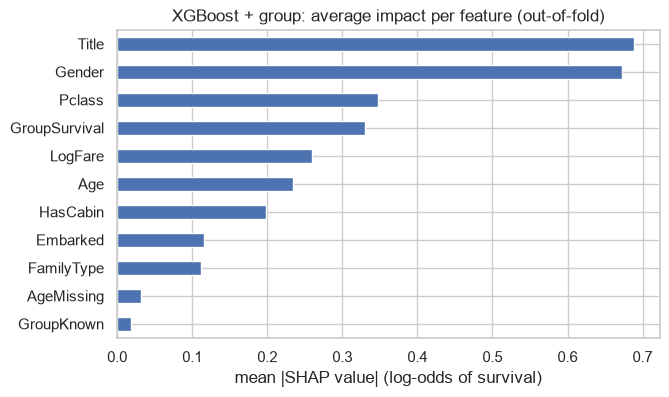

In [4]:
def original_feature(name):
    """'Gender_male' -> 'Gender'; engineered numeric and flag columns keep their name."""
    return next((c for c in CATEGORICAL_FEATURES if name.startswith(f"{c}_")), name)


shap_frame = pd.DataFrame(shap_values, columns=feature_names, index=X.index)
grouped = shap_frame.T.groupby(original_feature).sum().T
importance = grouped.abs().mean().sort_values(ascending=False).rename("mean_abs_shap").round(4)
importance.to_frame().to_csv(REPORT_DIR / "shap_importance.csv", index_label="feature")

fig, ax = plt.subplots(figsize=(7, 4))
importance[::-1].plot.barh(ax=ax, color="#4c72b0")
ax.set_xlabel("mean |SHAP value| (log-odds of survival)")
ax.set_title("XGBoost + group: average impact per feature (out-of-fold)")
save_fig(fig, "shap_importance")
importance.to_frame()

## 3. Direction: the beeswarm

One dot per passenger and column. Position = contribution to the log-odds, colour = the column's value (red high,
blue low; unscaled for `Age`, `LogFare` and `GroupSurvival`).

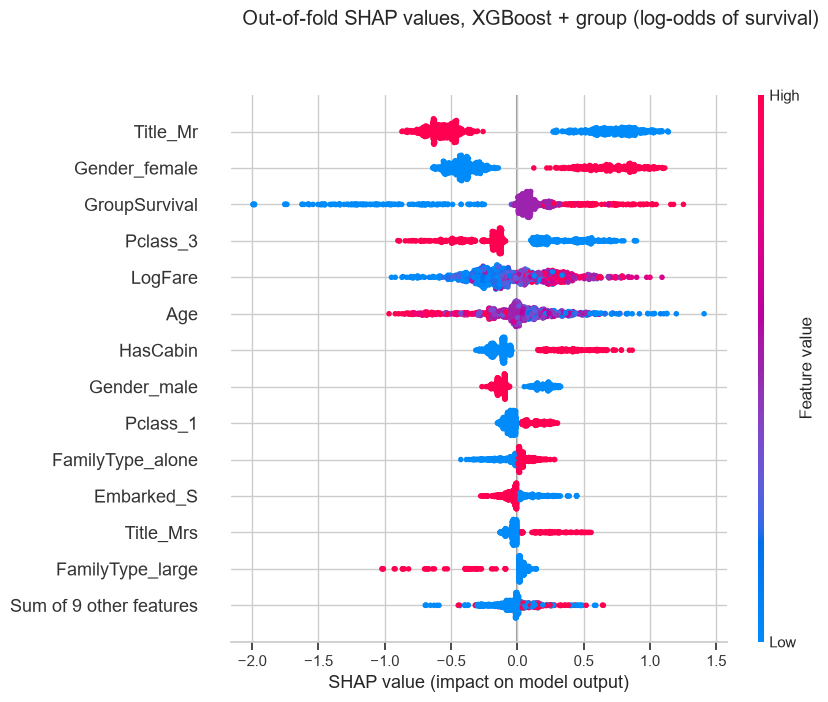

In [5]:
oof = shap.Explanation(values=shap_values, base_values=base_values,
                       data=raw_columns.to_numpy(), feature_names=feature_names)
shap.plots.beeswarm(oof, max_display=14, show=False)
fig = plt.gcf()
fig.suptitle("Out-of-fold SHAP values, XGBoost + group (log-odds of survival)", y=1.0)
save_fig(fig, "shap_beeswarm")
plt.show()

## 4. The group feature, by gender

Notebook 04 found the feature helps women whose group died and fails for men whose group survived. Below:
the contribution of `GroupSurvival` against its value, for passengers with a known group member, split by gender.

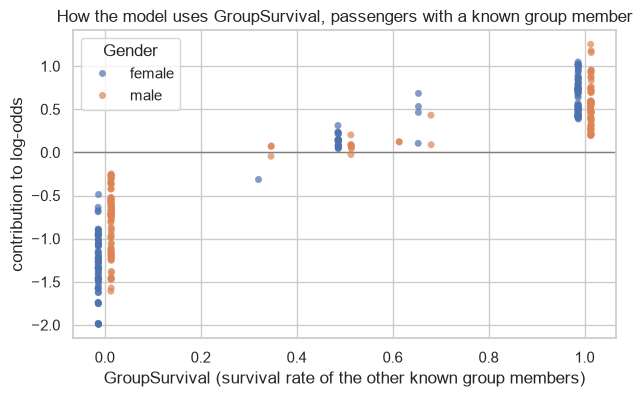

In [6]:
known = raw_columns["GroupKnown"] == 1
plot_data = pd.DataFrame({
    "GroupSurvival": raw_columns.loc[known, "GroupSurvival"],
    "SHAP of GroupSurvival": shap_frame.loc[known, "GroupSurvival"],
    "Gender": X.loc[known, "Gender"],
})
fig, ax = plt.subplots(figsize=(7, 4))
sns.stripplot(data=plot_data, x="GroupSurvival", y="SHAP of GroupSurvival", hue="Gender", dodge=True,
              native_scale=True, jitter=0.02, alpha=0.7, ax=ax)
ax.axhline(0, color="grey", lw=1)
ax.set_xlabel("GroupSurvival (survival rate of the other known group members)")
ax.set_ylabel("contribution to log-odds")
ax.set_title("How the model uses GroupSurvival, passengers with a known group member")
save_fig(fig, "shap_group_survival")
plt.show()

In [7]:
def bucket(rate, is_known):
    if not is_known:
        return "no known group member"
    if rate == 0:
        return "all known members died"
    if rate == 1:
        return "all known members survived"
    return "mixed"


buckets = pd.Series([bucket(r, k) for r, k in zip(raw_columns["GroupSurvival"], known)], index=X.index)
group_effect = shap_frame["GroupSurvival"] + shap_frame["GroupKnown"]
predicted = (margins > 0).astype(int)
table = pd.DataFrame({
    "Gender": X["Gender"], "bucket": buckets, "group_shap": group_effect,
    "predicted_survival": predicted, "survived": y, "correct": predicted == y,
}).groupby(["Gender", "bucket"]).agg(
    count=("survived", "size"),
    mean_group_shap=("group_shap", "mean"),
    predicted_survival=("predicted_survival", "mean"),
    actual_survival=("survived", "mean"),
    accuracy=("correct", "mean"),
).round(3)
table

count  mean_group_shap  predicted_survival  \
Gender bucket                                                                   
female all known members died         69           -1.266               0.275   
       all known members survived     66            0.684               1.000   
       mixed                          26            0.170               0.962   
       no known group member         153            0.175               0.928   
male   all known members died         83           -0.784               0.000   
       all known members survived     68            0.551               0.368   
       mixed                          14            0.125               0.214   
       no known group member         412            0.049               0.036   

                                   actual_survival  accuracy  
Gender bucket                                                 
female all known members died                0.304     0.884  
       all known members survived            1.000     1.000  
       mixed                                 0.923     0.885  
       no known group member                 0.797     0.765  
male   all known members died                0.060     0.940  
       all known members survived            0.426     0.706  
       mixed                                 0.571     0.643  
       no known group member                 0.163     0.835

Notebook 04 left one guess unchecked: the men whose known group members all survived might be mostly boys.
The title separates boys (`Master`) from adult men (`Mr`).

In [8]:
titles = make_preprocessor()[:-1].fit_transform(X)["Title"]
men_survived_group = (X["Gender"] == "male") & (buckets == "all known members survived")
pd.DataFrame({"Title": titles[men_survived_group], "survived": y[men_survived_group],
              "correct": (predicted == y)[men_survived_group],
              "group_shap": group_effect[men_survived_group]}).groupby("Title").agg(
    count=("survived", "size"), actual_survival=("survived", "mean"),
    accuracy=("correct", "mean"), mean_group_shap=("group_shap", "mean")).round(3)

,count,actual_survival,accuracy,mean_group_shap
Title,,,,
Master,14,0.929,0.929,0.679
Mr,50,0.300,0.700,0.507
Rare,4,0.250,0.000,0.653


## 5. One passenger, step by step

Selection rule, fixed before looking: the 3rd-class woman with the most negative `GroupSurvival` contribution.
The waterfall starts at the base value and adds one contribution per column until it reaches the model's log-odds.

PassengerId 542: survived=0, predicted probability=0.05


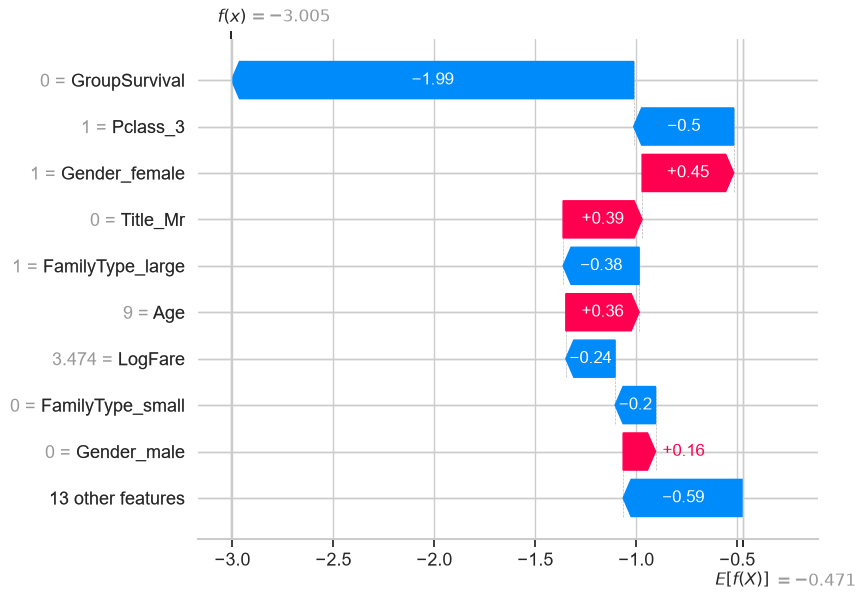

In [9]:
women_3rd = X.index[(X["Gender"] == "female") & (X["Pclass"] == 3)]
row = shap_frame.loc[women_3rd, "GroupSurvival"].idxmin()
position = X.index.get_loc(row)
print(f"PassengerId {X.loc[row, 'PassengerId']}: survived={y.loc[row]}, "
      f"predicted probability={1 / (1 + np.exp(-margins[position])):.2f}")
shap.plots.waterfall(oof[position], max_display=10, show=False)
fig = plt.gcf()
save_fig(fig, "shap_waterfall_example")
plt.show()

## 6. Findings

**The explanations are valid.** The five fold models reproduce notebook 04's out-of-fold accuracy (0.8373), and
base value + SHAP values match every passenger's log-odds (largest error 2.6e-6).

**Global ranking (mean |SHAP|, log-odds):** `Title` 0.69, `Gender` 0.67, `Pclass` 0.35, `GroupSurvival` 0.33,
`LogFare` 0.26, `Age` 0.23, `HasCabin` 0.20. Permutation importance in notebook 03 ranked `Title` far above
`Gender` and `Cabin` near zero. The difference is correlation: SHAP splits credit between features that carry the
same information (title and gender; `HasCabin`, class and fare; cabin is missing for ~98% of 3rd class), while
permutation importance gives little to a feature whose information survives in another column. Neither ranking is
"the" importance; they answer different questions.

**The group feature works in both directions.** All known members died: −1.27 log-odds for women and −0.78 for men.
All survived: +0.68 for women, +0.55 for men. Women whose known group died survive only 30% of the time, and the
model gets 88% of them right: this is the gain notebook 04 found for women in 3rd class.

**Men whose group survived are not a failure of the feature.** Their survival is 43% (vs 16% for men without a known
group member), so the feature is informative, but the group is close to a coin flip and accuracy is 71%. Notebook
04's guess is confirmed: the boys (`Master`, 14) survive 93% and are predicted correctly 93% of the time; the adult
men (`Mr`, 50) survive 30% and the feature cannot tell which of them did.

**Caveats.** SHAP describes this model, not the causes of survival. Values are tree-path-dependent log-odds from
five different fold models (base values −0.50 to −0.47). Correlated features share credit, so single-column values
should not be over-read.
